# 03 · Algorithm Selection & Model Building: PageClassifier

**Task.** Classify every page of an annual report by type. The KPI extractor uses this in two ways:
it reads numbers from the *financial-statement* pages, and it detects the reporting unit
(₹ crore / lakh / million) from those pages. Today both rely on brittle heading rules.

**Data.** `pages_clean.jsonl` from notebook 01: 2,199 pages, 4 companies, weak (rule-based) labels.

**What this notebook does**
1. Defines a leakage-free validation scheme.
2. Compares six algorithms on the original 10-class task.
3. Uses error analysis to justify the label taxonomy the downstream task actually needs.
4. Compares the algorithms again on that taxonomy.
5. Runs a feature ablation (text vs structural vs heading features).
6. Compares ways of handling class imbalance (none / class weights / SMOTE).
7. Tunes hyperparameters with grouped grid search.
8. Selects the final model and records the justification.

The final held-out evaluation is in **notebook 04**. The test company (Bharti Airtel) is never used here.

In [1]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from ml.paths import FIGURES_DIR, REPORTS_DIR
from ml.models.page_clf import (COARSE, COARSE_LABELS, STRUCT_FEATURES, candidates, features, lightgbm,
                                load_pages, present_labels)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
SELECTION = {}


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"03_{name}.png", dpi=130)
    plt.show()

## 1. Data and validation design

* **Development set** = the train and validation companies from notebook 01. The **test** company is
  locked away until notebook 04.
* **Leave-One-Company-Out cross-validation.** Each fold trains on all pages of *n−1* companies and
  validates on the remaining company. EDA §5.3 showed that pages share company-specific templates and
  vocabulary, so a random K-fold split would leak information and overstate every score.
* **Primary metric: macro-F1.** The classes are imbalanced 92:1, and the rare statement pages are the
  ones that matter most. We also report accuracy, balanced accuracy, the standard deviation across folds,
  and fit time.

In [2]:
pages = load_pages()
dev = pages[pages.split != "test"].reset_index(drop=True)
test_companies = sorted(pages.loc[pages.split == "test", "company"].unique())
X, groups = dev, dev.company
cv = LeaveOneGroupOut()
print(f"development pages: {len(dev)}  companies: {sorted(dev.company.unique())}")
print(f"held out for notebook 04: {test_companies}")
pd.crosstab(dev.label, dev.company)

development pages: 1898  companies: ['ADARSH PLANT PROTECT LIMITED', 'Adani Enterprises Ltd.', 'Hindustan Aeronautics Ltd.']
held out for notebook 04: ['Bharti Airtel Ltd.']


company,ADARSH PLANT PROTECT LIMITED,Adani Enterprises Ltd.,Hindustan Aeronautics Ltd.
label,,,
auditor_report,13,14,116
balance_sheet,1,7,6
cash_flow,0,5,8
corporate_governance,42,110,18
directors_report,0,60,175
equity_changes,1,4,4
mda,5,6,26
notes,34,374,299
other,4,413,123


In [3]:
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy", "balanced_acc": "balanced_accuracy"}


def evaluate(models: dict, y, X=X) -> pd.DataFrame:
    rows = []
    for name, model in models.items():
        t = time.time()
        r = cross_validate(model, X, y, groups=groups, cv=cv, scoring=SCORING, n_jobs=1)
        rows.append({
            "model": name,
            "macro_f1": r["test_macro_f1"].mean(), "macro_f1_std": r["test_macro_f1"].std(),
            "accuracy": r["test_accuracy"].mean(), "balanced_acc": r["test_balanced_acc"].mean(),
            "fit_s": r["fit_time"].mean(), "wall_s": time.time() - t,
            "folds": np.round(r["test_macro_f1"], 3).tolist(),
        })
    return pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)


def plot_comparison(res, title, name):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    order = res.sort_values("macro_f1").model
    r = res.set_index("model").loc[order]
    ax.barh(r.index, r.macro_f1, xerr=r.macro_f1_std, color=sns.color_palette()[0], capsize=3)
    for i, (v, s) in enumerate(zip(r.macro_f1, r.macro_f1_std)):
        ax.text(v + s + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlabel("macro-F1 (mean ± std over companies)")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    save(name)

## 2. The candidate algorithms

| Algorithm | Why it is a candidate | Feature scaling |
|---|---|---|
| Majority baseline | Floor that every real model must beat | none |
| Complement Naive Bayes | Classic, fast text classifier; designed for imbalanced text data | min-max (needs non-negative inputs) |
| Logistic Regression | Linear, probabilistic and interpretable; strong on TF-IDF | Yeo-Johnson + standardise |
| Linear SVM | Max-margin linear classifier; state of the art for sparse text | Yeo-Johnson + standardise |
| Random Forest | Non-linear bagging ensemble that captures feature interactions | none (scale-invariant) |
| LightGBM | Gradient-boosted trees; strong on mixed sparse and dense features | none (scale-invariant) |

Every model gets the same inputs: TF-IDF (word 1–2-grams) of the cleaned page text plus the 9 structural
features from notebook 01. The class-imbalance weighting is `class_weight="balanced"`, as decided in
notebook 01 §7.

## 3. Experiment 1: 10-class page type

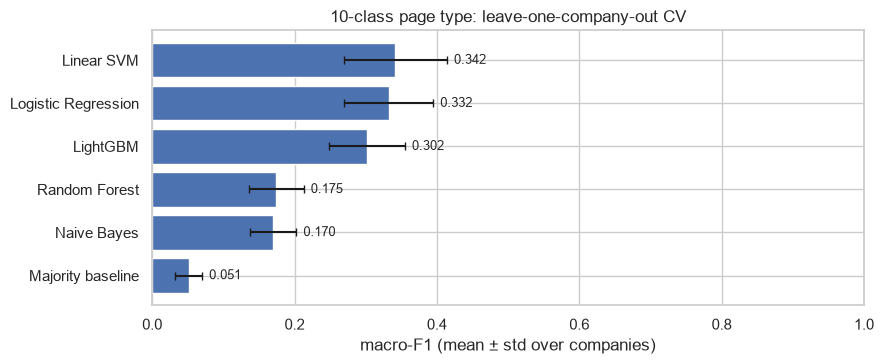

,model,macro_f1,macro_f1_std,accuracy,balanced_acc,fit_s,wall_s,folds
0,Linear SVM,0.342,0.073,0.449,0.451,1.431,4.897,"[0.253, 0.431, 0.34]"
1,Logistic Regression,0.332,0.063,0.429,0.425,2.508,8.123,"[0.254, 0.334, 0.408]"
2,LightGBM,0.302,0.053,0.382,0.423,14.131,43.181,"[0.238, 0.368, 0.299]"
3,Random Forest,0.175,0.038,0.405,0.265,1.664,5.850,"[0.189, 0.212, 0.122]"
4,Naive Bayes,0.170,0.033,0.410,0.247,0.629,2.484,"[0.215, 0.139, 0.156]"
5,Majority baseline,0.051,0.019,0.289,0.114,0.601,2.448,"[0.072, 0.054, 0.027]"


In [4]:
res10 = evaluate(candidates(), dev.label)
plot_comparison(res10, "10-class page type: leave-one-company-out CV", "algos_10class")
res10.round(3)

### Error analysis: where does the best 10-class model fail?

,f1,support,share of labels from carry-forward
balance_sheet,0.538,14,0.000
profit_loss,0.218,30,0.000
cash_flow,0.583,13,0.000
equity_changes,0.700,9,0.000
notes,0.809,707,0.219
auditor_report,0.504,143,0.867
directors_report,0.163,235,0.940
mda,0.000,37,0.865
corporate_governance,0.272,170,0.918
other,0.064,540,0.000


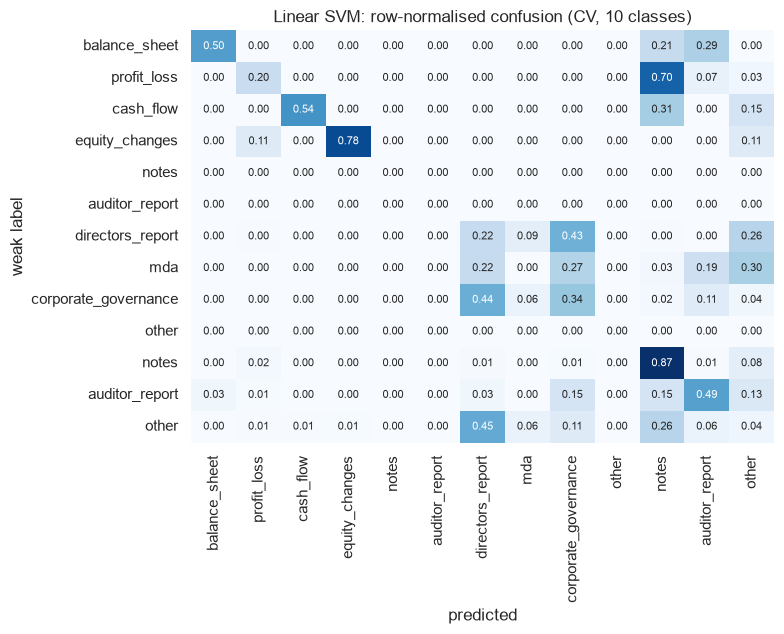

In [5]:
best10 = res10.model[0]
pred10 = cross_val_predict(candidates()[best10], X, dev.label, groups=groups, cv=cv)
labs10 = present_labels(dev.label)
per_class = pd.DataFrame({
    "f1": f1_score(dev.label, pred10, labels=labs10, average=None, zero_division=0),
    "support": dev.label.value_counts().reindex(labs10).values,
    "share of labels from carry-forward": dev.groupby("label").label_source.apply(lambda s: (s == "carry").mean()).reindex(labs10).values,
}, index=labs10).round(3)
display(per_class)

cm = confusion_matrix(dev.label, pred10, labels=labs10, normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labs10, yticklabels=labs10, ax=ax, cbar=False, annot_kws={"size": 8})
ax.set_xlabel("predicted")
ax.set_ylabel("weak label")
ax.set_title(f"{best10}: row-normalised confusion (CV, 10 classes)")
save("confusion_10class")

In [6]:
narr = ["directors_report", "corporate_governance", "mda", "other"]
stmt = ["balance_sheet", "cash_flow", "equity_changes", "notes"]
print(f"mean F1 of statement/notes classes : {per_class.loc[stmt, 'f1'].mean():.2f}")
print(f"mean F1 of narrative/other classes : {per_class.loc[narr, 'f1'].mean():.2f}")
print(f"carry-forward share in narrative classes: {per_class.loc[narr[:3], 'share of labels from carry-forward'].mean():.0%}")

mean F1 of statement/notes classes : 0.69
mean F1 of narrative/other classes : 0.11
carry-forward share in narrative classes: 91%


**Findings**
* The **statement and notes classes are learnable**: their labels come from headings printed on every page.
* The **narrative classes** (Directors' Report, Corporate Governance, MD&A, other) are confused with each
  other. Most of their labels come from the *carry-forward* rule, which assumes a section continues
  until the next heading. This is exactly where weak supervision is noisiest: annexures, BRSR pages and
  CSR tables inside the Directors' Report are labelled as the report itself.
  The model is being asked to reproduce label noise.
* Downstream, the KPI pipeline never distinguishes Directors' Report from Corporate Governance. It needs
  *statement / notes / auditor's report / narrative / other*.

**Decision.** We train on a **5-class taxonomy** that matches the downstream use. It merges the
narrative sections, and it merges the four primary statements into `statement`, which is too rare to
learn as four separate classes from 3 companies. This choice comes from the error analysis above, not
from trying to raise the score.

In [7]:
dev["coarse"] = dev.label.map(COARSE)
dev.coarse.value_counts().reindex(COARSE_LABELS).to_frame("pages").T

coarse,statement,notes,auditor_report,narrative,other
pages,66,707,143,442,540


## 4. Experiment 2: 5-class taxonomy

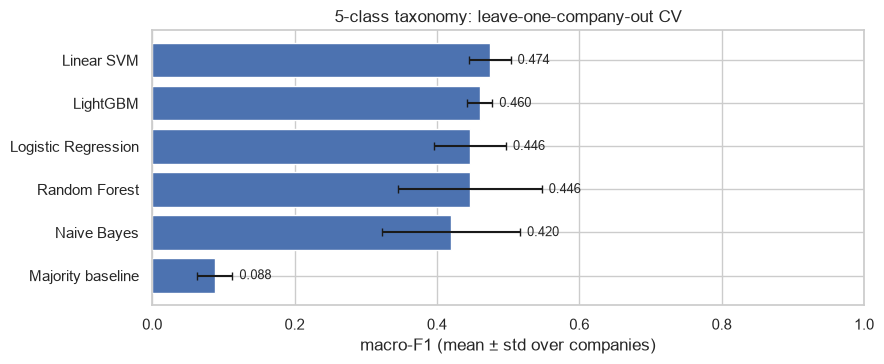

,model,macro_f1,macro_f1_std,accuracy,balanced_acc,fit_s,wall_s,folds
0,Linear SVM,0.474,0.029,0.623,0.538,1.286,4.473,"[0.435, 0.482, 0.506]"
1,LightGBM,0.460,0.018,0.584,0.557,8.454,26.130,"[0.462, 0.437, 0.48]"
2,Logistic Regression,0.446,0.050,0.580,0.516,1.983,6.588,"[0.403, 0.419, 0.517]"
3,Random Forest,0.446,0.101,0.641,0.520,1.655,5.826,"[0.586, 0.352, 0.399]"
4,Naive Bayes,0.420,0.097,0.572,0.488,0.632,2.489,"[0.554, 0.331, 0.375]"
5,Majority baseline,0.088,0.025,0.289,0.200,0.644,2.530,"[0.101, 0.109, 0.053]"


In [8]:
y = dev.coarse
res5 = evaluate(candidates(), y)
plot_comparison(res5, "5-class taxonomy: leave-one-company-out CV", "algos_5class")
res5.round(3)

## 5. Experiment 3: feature ablation

Which inputs carry the signal? We test the two strongest model families with: text only, structural
only, text + structural, and text + structural + **heading features**. The heading features are
character n-grams of the page top *before* running-header removal (notebook 01 §7).

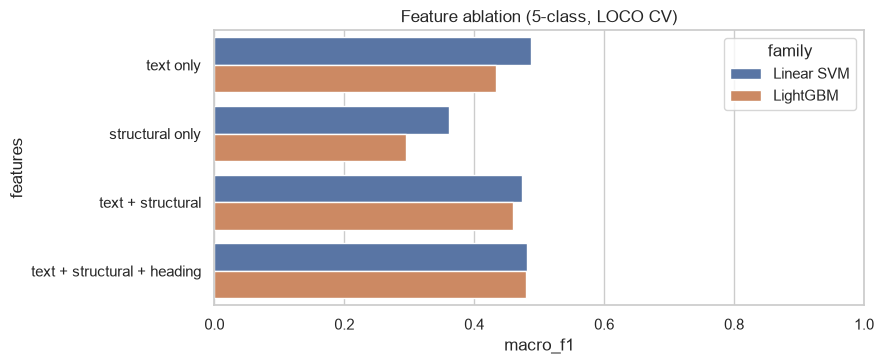

family,LightGBM,Linear SVM
features,,
text only,0.433,0.487
structural only,0.294,0.361
text + structural,0.460,0.474
text + structural + heading,0.480,0.480


In [9]:
from sklearn.linear_model import LogisticRegression


def svm(**f):
    return Pipeline([("f", features("linear", **f)), ("m", LinearSVC(C=0.5, class_weight="balanced", max_iter=5000))])


def lgbm(**f):
    return Pipeline([("f", features("tree", max_features=5000, **f)), ("m", lightgbm())])


variants = {
    "text only": dict(text=True, struct=False),
    "structural only": dict(text=False, struct=True),
    "text + structural": dict(text=True, struct=True),
    "text + structural + heading": dict(text=True, struct=True, head=True),
}
abl_rows = []
for vname, kw in variants.items():
    for fam, make in [("Linear SVM", svm), ("LightGBM", lgbm)]:
        r = evaluate({f"{fam} · {vname}": make(**kw)}, y).iloc[0]
        abl_rows.append({"family": fam, "features": vname, "macro_f1": r.macro_f1, "std": r.macro_f1_std})
ablation = pd.DataFrame(abl_rows)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(data=ablation, y="features", x="macro_f1", hue="family", ax=ax)
ax.set_title("Feature ablation (5-class, LOCO CV)")
ax.set_xlim(0, 1)
save("ablation")
ablation.pivot(index="features", columns="family", values="macro_f1").loc[list(variants)].round(3)

In [10]:
# Carry the best feature set of the leading family (Linear SVM) into the next experiments
svm_rows = ablation[ablation.family == "Linear SVM"].sort_values("macro_f1", ascending=False)
best_feat = svm_rows.iloc[0]
feat_kw = variants[best_feat.features]
spread = svm_rows.macro_f1.max() - svm_rows[svm_rows.features != "structural only"].macro_f1.min()
print(f"best Linear SVM feature set: {best_feat.features} (macro-F1 {best_feat.macro_f1:.3f})")
print(f"spread between text-based variants: {spread:.3f} (fold std ≈ {best_feat['std']:.3f}) → "
      f"{'within noise' if spread < best_feat['std'] else 'meaningful'}")
SELECTION["feature_ablation"] = ablation.round(4).to_dict("records")

best Linear SVM feature set: text only (macro-F1 0.487)
spread between text-based variants: 0.013 (fold std ≈ 0.042) → within noise


**Reading the ablation.**
* The 9 structural features alone score far above the majority baseline, so they carry real signal.
* Once TF-IDF is present, they add nothing for the linear SVM: the statement-page vocabulary already
  encodes "numeric table".
* The heading n-grams help LightGBM slightly but not the SVM.
* The differences between the text-based variants are within one fold-standard-deviation. Following the
  principle of parsimony, the next experiments use the best SVM feature set found above.

## 6. Experiment 4: handling class imbalance

`statement` pages are about 3% of the corpus. We compare three strategies, all applied **inside** each
training fold, never before the split:
* no correction;
* `class_weight="balanced"`, which reweights the loss;
* **SMOTE**, which synthesises minority examples by interpolating between neighbours in feature space
  (imblearn pipeline, so oversampling only ever sees training-fold data).

In [11]:
imb_models = {
    "no correction": Pipeline([("f", features("linear", **feat_kw)), ("m", LinearSVC(C=0.5, max_iter=5000))]),
    "class weights": Pipeline([("f", features("linear", **feat_kw)), ("m", LinearSVC(C=0.5, class_weight="balanced", max_iter=5000))]),
    "SMOTE": ImbPipeline([("f", features("linear", **feat_kw)), ("smote", SMOTE(k_neighbors=3, random_state=42)),
                          ("m", LinearSVC(C=0.5, max_iter=5000))]),
}
imb = evaluate(imb_models, y)

# Recall on the rare class is what matters for KPI extraction
for name, m in imb_models.items():
    p = cross_val_predict(m, X, y, groups=groups, cv=cv)
    imb.loc[imb.model == name, "statement_recall"] = ((p == "statement") & (y == "statement")).sum() / (y == "statement").sum()
SELECTION["imbalance"] = imb.drop(columns="folds").round(4).to_dict("records")
imb.drop(columns="folds").round(3)

,model,macro_f1,macro_f1_std,accuracy,balanced_acc,fit_s,wall_s,statement_recall
0,class weights,0.487,0.042,0.587,0.578,0.688,2.682,0.530
1,SMOTE,0.482,0.048,0.591,0.575,0.775,2.937,0.515
2,no correction,0.451,0.023,0.573,0.492,0.710,2.744,0.409


In [12]:
best_imb = imb.iloc[0].model
print(f"best imbalance strategy: {best_imb}")

best imbalance strategy: class weights


## 7. Experiment 5: hyperparameter tuning (grouped grid search)

We tune the best model family with `GridSearchCV`, still using leave-one-company-out folds so that the
tuning cannot overfit to one company. Searched parameters:
* the SVM regularisation **C**;
* the TF-IDF **n-gram range** and **vocabulary size**.

In [13]:
base = imb_models[best_imb]
grid = {
    "m__C": [0.005, 0.01, 0.02, 0.05, 0.1, 0.3, 1.0],
    "f__text__ngram_range": [(1, 1), (1, 2)],
    "f__text__max_features": [5000, 15000],
}
t = time.time()
search = GridSearchCV(base, grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=False)
search.fit(X, y, groups=groups)
print(f"{len(search.cv_results_['params'])} configurations × {cv.get_n_splits(groups=groups)} folds in {time.time() - t:.0f}s")

gs = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
gs.head(8)

28 configurations × 3 folds in 13s


,params,mean_test_score,std_test_score,rank_test_score
23,"{'f__text__max_features': 15000, 'f__text__ngr...",0.503913,0.057787,1
8,"{'f__text__max_features': 5000, 'f__text__ngra...",0.500683,0.051370,2
22,"{'f__text__max_features': 15000, 'f__text__ngr...",0.498222,0.055214,3
24,"{'f__text__max_features': 15000, 'f__text__ngr...",0.498207,0.055173,4
25,"{'f__text__max_features': 15000, 'f__text__ngr...",0.495917,0.052743,5
9,"{'f__text__max_features': 5000, 'f__text__ngra...",0.494993,0.051784,6
1,"{'f__text__max_features': 5000, 'f__text__ngra...",0.493212,0.058040,7
16,"{'f__text__max_features': 15000, 'f__text__ngr...",0.492098,0.064983,8


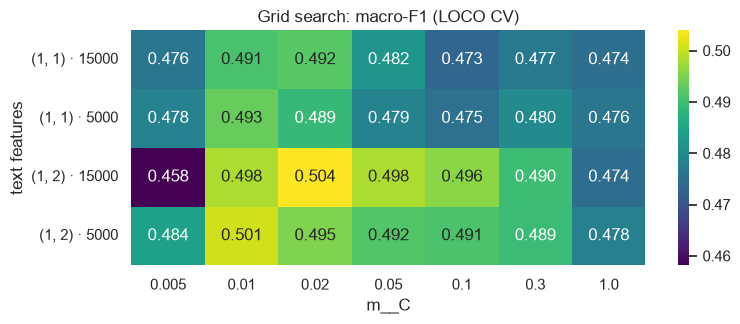

best params: {'f__text__max_features': 15000, 'f__text__ngram_range': (1, 2), 'm__C': 0.02} → macro-F1 0.504 (default config 0.474)


In [14]:
heat = pd.DataFrame([{**p, "score": s} for p, s in zip(search.cv_results_["params"], search.cv_results_["mean_test_score"])])
heat["text features"] = heat["f__text__ngram_range"].astype(str) + " · " + heat["f__text__max_features"].astype(str)
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.heatmap(heat.pivot(index="text features", columns="m__C", values="score"), annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_title("Grid search: macro-F1 (LOCO CV)")
save("gridsearch")

best_params = search.best_params_
default_score = res5.set_index("model").loc["Linear SVM", "macro_f1"]
print(f"best params: {best_params} → macro-F1 {search.best_score_:.3f} (default config {default_score:.3f})")

## 8. Final model selection

In [15]:
summary = pd.concat([
    res5.assign(stage="algorithm comparison")[["stage", "model", "macro_f1", "macro_f1_std", "accuracy", "balanced_acc", "fit_s"]],
    pd.DataFrame([{"stage": "tuned", "model": f"Linear SVM (tuned, {best_imb})", "macro_f1": search.best_score_,
                   "macro_f1_std": float(gs.iloc[0].std_test_score)}]),
]).reset_index(drop=True)
summary.round(3)

,stage,model,macro_f1,macro_f1_std,accuracy,balanced_acc,fit_s
0,algorithm comparison,Linear SVM,0.474,0.029,0.623,0.538,1.286
1,algorithm comparison,LightGBM,0.460,0.018,0.584,0.557,8.454
2,algorithm comparison,Logistic Regression,0.446,0.050,0.580,0.516,1.983
3,algorithm comparison,Random Forest,0.446,0.101,0.641,0.520,1.655
4,algorithm comparison,Naive Bayes,0.420,0.097,0.572,0.488,0.632
5,algorithm comparison,Majority baseline,0.088,0.025,0.289,0.200,0.644
6,tuned,"Linear SVM (tuned, class weights)",0.504,0.058,NaN,NaN,NaN


**Selection criteria**, in order:
1. Mean macro-F1 across held-out companies.
2. Stability, i.e. a low standard deviation across companies. A model used on unseen companies must not
   be good for one company and poor for another.
3. Inference cost: the classifier runs on every page of every upload, on CPU.
4. Interpretability: per-class feature weights can be inspected.

The cell below records the decision. Notebook 04 refits the selected configuration on all development
data and evaluates it once on the held-out company.

In [16]:
final_config = {
    "algorithm": "Linear SVM",
    "imbalance": best_imb,
    "features": best_feat.features,
    "feature_flags": feat_kw,
    "params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
    "taxonomy": COARSE_LABELS,
    "cv_macro_f1": round(float(search.best_score_), 4),
}
lin = res5.set_index("model")
runner_up = lin.drop(index=["Linear SVM", "Majority baseline"]).macro_f1.idxmax()
final_config["justification"] = (
    f"Linear SVM had the best mean macro-F1 in the algorithm comparison ({lin.loc['Linear SVM', 'macro_f1']:.3f} "
    f"± {lin.loc['Linear SVM', 'macro_f1_std']:.3f}) vs runner-up {runner_up} ({lin.loc[runner_up, 'macro_f1']:.3f} "
    f"± {lin.loc[runner_up, 'macro_f1_std']:.3f}), trains in ~{lin.loc['Linear SVM', 'fit_s']:.1f}s vs "
    f"{lin.loc['LightGBM', 'fit_s']:.1f}s for LightGBM, and exposes per-class feature weights. Features: {best_feat.features} "
    f"(ablation), imbalance: {best_imb}. Tuned with grouped grid search "
    f"to macro-F1 {search.best_score_:.3f}."
)
print(json.dumps(final_config, indent=1))

SELECTION.update({
    "validation": "Leave-One-Company-Out CV on development companies",
    "dev_companies": sorted(dev.company.unique().tolist()),
    "algorithms_10class": res10.drop(columns="folds").round(4).to_dict("records"),
    "algorithms_5class": res5.drop(columns="folds").round(4).to_dict("records"),
    "per_class_10class": per_class.reset_index(names="label").to_dict("records"),
    "gridsearch_top": [{"params": {k: str(v) for k, v in r.params.items()}, "score": round(r.mean_test_score, 4)}
                       for r in gs.head(5).itertuples()],
    "final": final_config,
})
(REPORTS_DIR / "model_selection.json").write_text(json.dumps(SELECTION, indent=1, default=float), encoding="utf-8")
print("wrote model_selection.json")

{
 "algorithm": "Linear SVM",
 "imbalance": "class weights",
 "features": "text only",
 "feature_flags": {
  "text": true,
  "struct": false
 },
 "params": {
  "f__text__max_features": 15000,
  "f__text__ngram_range": [
   1,
   2
  ],
  "m__C": 0.02
 },
 "taxonomy": [
  "statement",
  "notes",
  "auditor_report",
  "narrative",
  "other"
 ],
 "cv_macro_f1": 0.5039,
 "justification": "Linear SVM had the best mean macro-F1 in the algorithm comparison (0.474 \u00b1 0.029) vs runner-up LightGBM (0.460 \u00b1 0.018), trains in ~1.3s vs 8.5s for LightGBM, and exposes per-class feature weights. Features: text only (ablation), imbalance: class weights. Tuned with grouped grid search to macro-F1 0.504."
}
wrote model_selection.json


## Summary

| Step | Outcome |
|---|---|
| Validation | Leave-One-Company-Out CV; the test company is untouched |
| 6 algorithms, 10 classes | All models beat the baseline; narrative classes are limited by carry-forward label noise |
| Taxonomy | 5 classes aligned with the KPI pipeline, justified by the error analysis |
| 6 algorithms, 5 classes | Ranking and stability table above |
| Feature ablation | Contribution of text, structural and heading features measured separately |
| Imbalance | No correction vs class weights vs SMOTE, applied inside each fold |
| Tuning | Grouped grid search over C, n-grams and vocabulary size |
| **Selected** | **Linear SVM**: best mean score, most stable, fastest, interpretable |